## Supervised Learning
## Goal: Predict avg_daily_sales using our training data

Focus on:
1. Dataset Overview 
2. identify missing columns  
3. Data Distribution...log transform...
(Features: population and density, median income, competitors nearby, walkability, traffic, jobs nearby, and business type.)
3.1 Target Variable Distribution
4. Features relationship with sales, correlations...
5. Model: Linear Regression, Decision Tree, Random Forest 
6. Compare validation Mean Absolute Error (MAE), Root Mean Squared (RMSE), R^2 
7. Test with test data set 


## Import Libraries

In [17]:
#import libraries for data handling and visualization plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Tools for missing values
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

import matplotlib.pyplot as plt

In [2]:
import sys
from pathlib import Path

current = Path.cwd().resolve()
print(current)

repo_root = next(
    parent
    for parent in (current, *current.parents)
    if (parent / "src" / "config.py").exists()
)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.config import TRAIN_DATA_PARQUET_PATH

/Users/yifang.kao/Desktop/mads/mads_milestone_two/src/supervised


# Data Overview


In [ ]:
#Read-in train dataset

#df = pd.read_parquet('../../data/modeling/train_data.parquet')
df = pd.read_parquet('../../'+TRAIN_DATA_PARQUET_PATH)

df.info
print(df.describe().round(2))

       avg_daily_sales  longitude  latitude  competitors_within_1_mi  \
count          8669.00    8669.00   8669.00                  8669.00   
mean           2349.19     -74.68     41.63                    44.38   
std            2886.29       1.65      1.11                    54.92   
min               0.41     -79.76     40.51                     0.00   
25%             669.08     -75.22     40.72                     6.00   
50%            1483.95     -73.93     40.89                    18.00   
75%            2929.67     -73.78     42.78                    67.00   
max           62358.43     -71.94     45.00                   249.00   

       aadt_count  aadt_lanes  dist_to_read_m  median_household_income  \
count     8647.00     8617.00         8667.00                  7788.00   
mean     11984.68        3.62           24.99                 93986.05   
std      11037.71        2.91           53.99                 48121.03   
min          2.00        1.00            0.00          

#### Number of Retailers and Features

In [4]:
# Number of features in the data
features = [data for data in df.select_dtypes("number").columns if data not in ["avg_daily_sales", "longitude", "latitude"]]

print('\n'f"{len(df)} retailers" ' & ' f"{len(features)} numeric features")


8669 retailers & 48 numeric features


In [5]:
#Convert all columns except "chain" and "bustype" to numeric to review missing values and impute missing values
string_cols = ["chain", "bustype", "region"]  # replace with your column names

# Keep these columns as pandas strings
df[string_cols] = df[string_cols].astype("string")

# Convert all remaining columns to numeric
numeric_cols = df.columns.difference(string_cols)
df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

print(df.dtypes)

agtno                                   int64
avg_daily_sales                       float64
chain                                  string
bustype                                string
longitude                             float64
latitude                              float64
bg_geoid                                int64
tract_geoid                             int64
region                                 string
competitors_within_1_mi               float64
aadt_count                            float64
aadt_functional_class                 float64
aadt_lanes                            float64
dist_to_read_m                        float64
median_household_income               float64
total_population                      float64
age_18_29_proportion                  float64
age_30_64_proportion                  float64
poverty_rate                          float64
bachelors_degree_proportion_25plus    float64
post_grad_degree_proportion_25plus    float64
labor_force_participation_rate    

## Missing Values

In [6]:
#percentage of missing data 
missing_data = (df[features].isna().mean() * 100).sort_values(ascending=False).round(2).astype(str) + '%'

print(missing_data)

D1C                                   18.34%
D1B                                   18.34%
NatWalkInd                            18.34%
D3A                                   18.34%
median_household_income               10.16%
poverty_rate                           1.26%
family_households_proportion           1.26%
owner_occupied_proportion              1.26%
no_vehicle_households_proportion       1.26%
unemployment_rate                      1.23%
age_30_64_proportion                   1.13%
post_grad_degree_proportion_25plus     1.13%
labor_force_participation_rate         1.13%
age_18_29_proportion                   1.13%
bachelors_degree_proportion_25plus     1.13%
aadt_lanes                              0.6%
total_population                       0.53%
commercial_places_within_1_mi          0.36%
community_places_within_1_mi           0.36%
aadt_count                             0.25%
wac_cns07                              0.08%
wac_cns17                              0.08%
wac_cns16 

Insight: Missing Values:
- Missing values will be filled with the median (imputation cell below), median will not be pulled by very large values in skewed columns

In [7]:
#Review missing values
summary = df.describe()

summary.loc['missing_values'] = df.isna().sum()
summary

#Export to CSV for full review
#summary.to_csv('/Users/brisabol/Documents/MADS/SIADS 696/train_missing_20261017.csv', index=True)

,agtno,avg_daily_sales,longitude,latitude,bg_geoid,tract_geoid,competitors_within_1_mi,aadt_count,aadt_functional_class,aadt_lanes,...,wac_cns14,wac_cns15,wac_cns16,wac_cns17,wac_cns18,wac_cns19,wac_cns20,wac_c000,wac_ce01_prop,wac_ce02_prop
count,8669.000000,8669.000000,8669.000000,8669.000000,8.669000e+03,8.669000e+03,8669.000000,8647.000000,8663.000000,8617.000000,...,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000
mean,87764.363940,2349.192381,-74.681130,41.630837,3.606444e+11,3.606444e+10,44.378706,11984.681277,14.505945,3.619937,...,80.036712,87.963057,190.077927,18.079081,104.319788,46.922766,133.643039,1292.232163,0.215783,0.321424
std,28887.512003,2886.293329,1.648507,1.113746,3.174182e+08,3.174182e+07,54.924672,11037.711299,3.094066,2.913371,...,429.751661,427.936950,989.100283,89.970491,238.059210,141.996281,1340.817884,4090.103197,0.099802,0.117556
min,2.000000,0.413333,-79.759770,40.511420,3.600100e+11,3.600100e+10,0.000000,2.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,70880.000000,669.078082,-75.222490,40.724830,3.604703e+11,3.604703e+10,6.000000,5436.000000,14.000000,2.000000,...,0.000000,0.000000,6.000000,0.000000,8.000000,5.000000,0.000000,152.000000,0.142857,0.245283
50%,101459.000000,1483.953425,-73.932190,40.890840,3.606102e+11,3.606102e+10,18.000000,9569.000000,16.000000,2.000000,...,5.000000,1.000000,28.000000,0.000000,34.000000,15.000000,0.000000,382.000000,0.208986,0.311834
75%,111444.000000,2929.672603,-73.777160,42.782530,3.608502e+11,3.608502e+10,67.000000,15712.000000,16.000000,4.000000,...,23.750000,60.750000,105.000000,5.000000,103.000000,37.000000,0.000000,952.000000,0.276281,0.387500
max,116515.000000,62358.432877,-71.943160,44.997930,3.612315e+11,3.612315e+10,249.000000,199411.000000,19.000000,33.000000,...,7969.000000,31117.000000,41063.000000,1746.000000,3528.000000,2008.000000,33461.000000,58601.000000,1.000000,1.000000
missing_values,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,22.000000,6.000000,52.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000


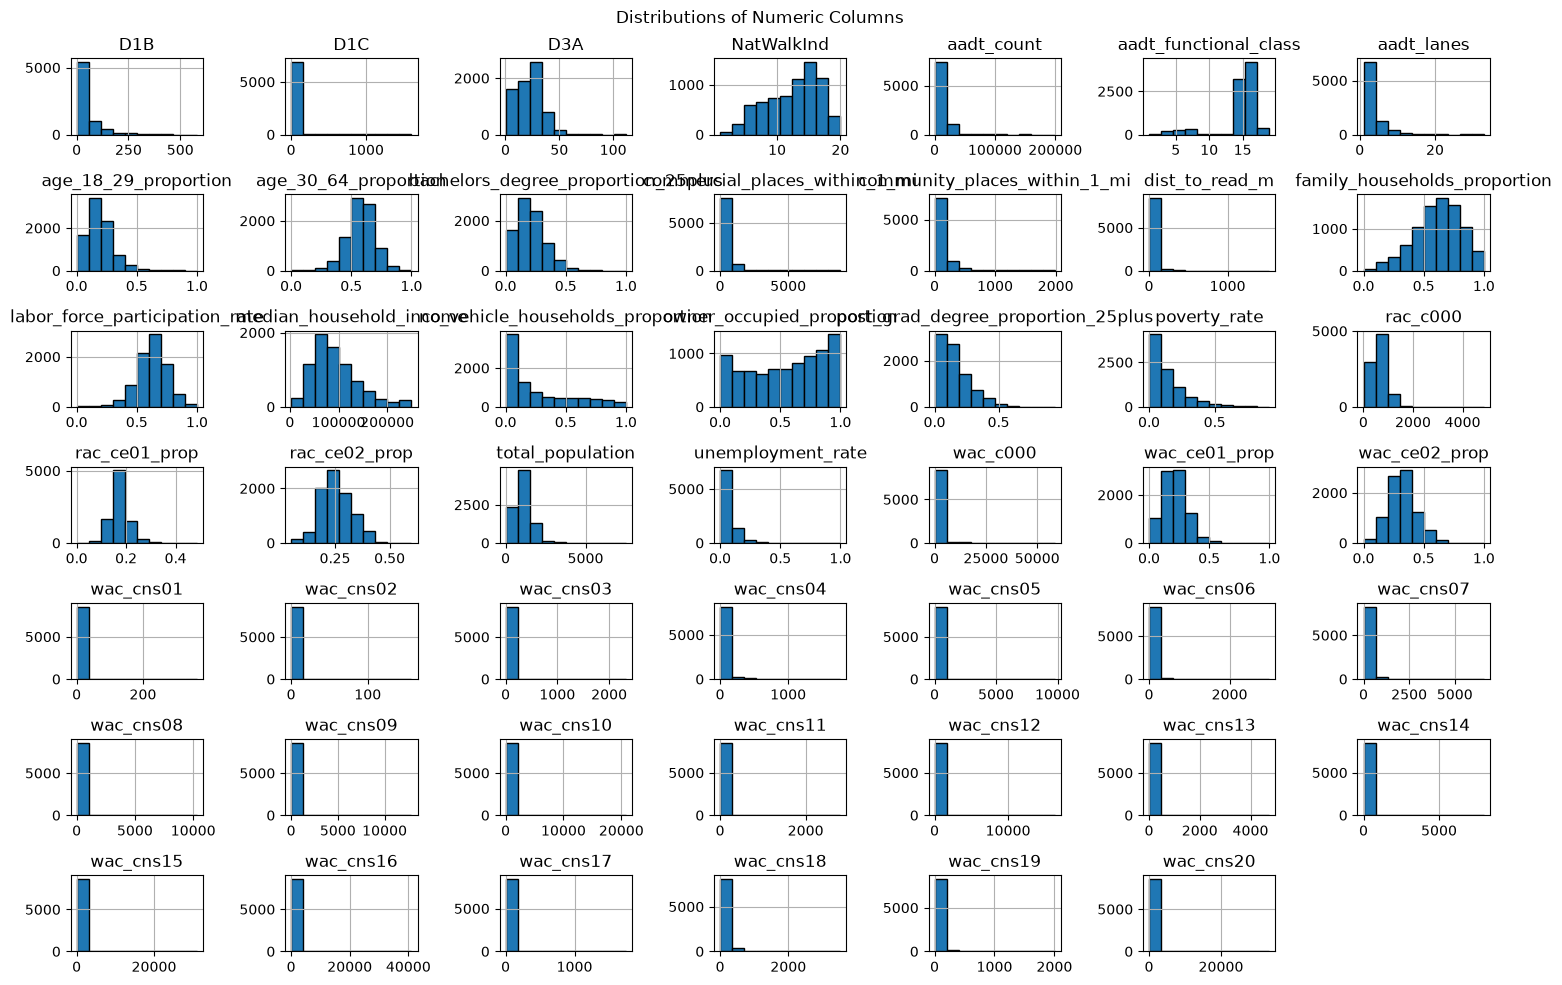

In [8]:
#Review histogram of columns to determin which method for imputation
#Ignore columns with no missing values and string type, including agtno to competitors_within_1_mi
ignore_columns = ["agtno", "avg_daily_sales", "chain", "bustype", "region", "longitude", "latitude",
                  "bg_geoid", "tract_geoid", "competitors_within_1_mi"]
numeric_columns2 = df.columns.difference(ignore_columns)

df[numeric_columns2].hist(
    bins=10,
    figsize=(15, 10),
    edgecolor="black"
)

plt.suptitle("Distributions of Numeric Columns")
plt.tight_layout()
plt.show()

Insights:
- Variables with that are very right skewed: "competitors_within_1_mi", "commercial_places_within_1_mi", "community_places_within_1_mi", "aadt_count", 
"total_population", "D1C", "rac_c000", "D1B", "wac_c000", "all the wac_cns" These columns will be log transformed. 
- This chart gives us an overview before preprocessing: medain to fill missing values, and log transform for skewed counts. 

In [ ]:
#Perform imputation of missing values on all columns except ignore_columns 

preprocessor = ColumnTransformer(
    transformers=[
        ("median_imputer",
         SimpleImputer(strategy="median"), numeric_columns2)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

preprocessor.set_output(transform="pandas")

df_imputed = preprocessor.fit_transform(df)

df_imputed

,D1B,D1C,D3A,NatWalkInd,aadt_count,aadt_functional_class,aadt_lanes,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,...,agtno,avg_daily_sales,chain,bustype,longitude,latitude,bg_geoid,tract_geoid,region,competitors_within_1_mi
0,32.606713,1406.135234,27.016522,10.500000,6085.0,17.0,2.0,0.201807,0.728916,0.271875,...,100006,2989.605479,independent,NYC NEWSSTAND,-73.98193,40.75969,360610125001,36061012500,New York City,224.0
1,10.594670,3.509165,22.618969,13.500000,31022.0,14.0,4.0,0.312210,0.640649,0.137688,...,100013,4147.939394,independent,GAS,-73.42486,40.69660,361031233044,36103123304,Long Island,23.0
2,10.594670,3.509165,22.618969,13.500000,22241.0,14.0,4.0,0.017117,0.813693,0.710994,...,100028,4000.453425,independent,CONV. STORE,-73.95721,40.76617,360610126014,36061012601,New York City,95.0
3,0.267987,0.014813,3.723396,4.666667,4290.0,7.0,5.0,0.076818,0.540466,0.061693,...,100047,1833.794521,independent,CONV. STORE,-74.02479,42.17531,360390811011,36039081101,Capital Region,0.0
4,0.328107,1.151738,3.380415,4.666667,19072.0,16.0,6.0,0.073548,0.587097,0.190798,...,100048,3552.153425,independent,CONV. STORE,-74.12407,41.32219,360710139003,36071013900,Mid-Hudson,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8664,181.854969,94.324428,27.472849,17.833333,1270.0,16.0,2.0,0.438384,0.537374,0.352014,...,99717,2825.932877,independent,CONV. STORE,-73.99624,40.72106,360610041006,36061004100,New York City,203.0
8665,28.402430,55.198067,26.636415,15.666667,6697.0,16.0,2.0,0.271547,0.609209,0.468305,...,99757,9046.871233,independent,DELI-GROCERY,-74.02671,40.62093,360470160004,36047016000,New York City,81.0
8666,65.538953,10.980348,17.368700,11.666667,7021.0,16.0,2.0,0.256367,0.657046,0.120654,...,99799,1332.806849,independent,DRUG STORE,-73.99264,40.61669,360470260002,36047026000,New York City,131.0
8667,42.172676,11.012160,28.916170,19.666667,5807.0,19.0,2.0,0.164565,0.617784,0.215573,...,99866,4740.328767,independent,GROCERY STORE,-73.81502,40.76230,360811167001,36081116700,New York City,108.0


In [10]:
#Check imputation

summary = df_imputed.describe()

summary.loc['missing_values'] = df_imputed.isna().sum()
summary

#Export to CSV for full review
#summary.to_csv('/Users/brisabol/Documents/MADS/SIADS 696/train_missing_check_20261017.csv', index=True)

,D1B,D1C,D3A,NatWalkInd,aadt_count,aadt_functional_class,aadt_lanes,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,...,wac_cns18,wac_cns19,wac_cns20,agtno,avg_daily_sales,longitude,latitude,bg_geoid,tract_geoid,competitors_within_1_mi
count,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,...,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8.669000e+03,8.669000e+03,8669.000000
mean,33.259495,23.387530,21.921696,12.717634,11978.550813,14.506979,3.610220,0.192004,0.579590,0.205486,...,104.263006,46.896989,133.535125,87764.363940,2349.192381,-74.681130,41.630837,3.606444e+11,3.606444e+10,44.378706
std,56.059413,117.459828,11.143850,3.756493,11024.365205,3.093245,2.907312,0.112022,0.115415,0.119002,...,237.971450,141.941831,1340.281750,28887.512003,2886.293329,1.648507,1.113746,3.174182e+08,3.174182e+07,54.924672
min,0.000000,0.000000,0.092342,1.000000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,2.000000,0.413333,-79.759770,40.511420,3.600100e+11,3.600100e+10,0.000000
25%,4.054697,1.211203,15.157034,10.166667,5440.000000,14.000000,2.000000,0.117647,0.514576,0.119597,...,8.000000,5.000000,0.000000,70880.000000,669.078082,-75.222490,40.724830,3.604703e+11,3.604703e+10,6.000000
50%,10.594670,3.509165,22.618969,13.500000,9569.000000,16.000000,2.000000,0.177368,0.584041,0.191323,...,34.000000,15.000000,0.000000,101459.000000,1483.953425,-73.932190,40.890840,3.606102e+11,3.606102e+10,18.000000
75%,33.576104,8.398180,28.100337,15.333333,15690.000000,16.000000,4.000000,0.243502,0.652715,0.275478,...,103.000000,37.000000,0.000000,111444.000000,2929.672603,-73.777160,42.782530,3.608502e+11,3.608502e+10,67.000000
max,580.668648,1607.530925,111.879823,20.000000,199411.000000,19.000000,33.000000,1.000000,1.000000,1.000000,...,3528.000000,2008.000000,33461.000000,116515.000000,62358.432877,-71.943160,44.997930,3.612315e+11,3.612315e+10,249.000000
missing_values,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000


In [11]:
#Log transformation of columns that are skewed (matches columns that received median imputation)

#cols = ["aadt_count", "aadt_functional_class", "aadt_lanes", "dist_to_read_m", "total_population",
#           "poverty_rate", "post_grad_degree_proportion_25plus", "unemployment_rate",
#           "no_vehicle_households_proportion", "D1B", "D1C", "commercial_places_within_1_mi", "community_places_within_1_mi",
#           "rac_c000", "wac_c000"] + [f"wac_cns{i:02d}" for i in range (1,21)]

#Log features in preprocess_super.py
LOG_FEATURES = ['competitors_within_1_mi', "commercial_places_within_1_mi", "aadt_count", 
                "total_population", "D1C", "rac_c000", 'D1B'] + [f"wac_cns{i:02d}" for i in range (1,21)]

df_imputed[LOG_FEATURES] = np.log1p(df_imputed[LOG_FEATURES])

df_imputed


,D1B,D1C,D3A,NatWalkInd,aadt_count,aadt_functional_class,aadt_lanes,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,...,agtno,avg_daily_sales,chain,bustype,longitude,latitude,bg_geoid,tract_geoid,region,competitors_within_1_mi
0,3.514726,7.249311,27.016522,10.500000,8.713746,17.0,2.0,0.201807,0.728916,0.271875,...,100006,2989.605479,independent,NYC NEWSSTAND,-73.98193,40.75969,360610125001,36061012500,New York City,5.416100
1,2.450545,1.506112,22.618969,13.500000,10.342484,14.0,4.0,0.312210,0.640649,0.137688,...,100013,4147.939394,independent,GAS,-73.42486,40.69660,361031233044,36103123304,Long Island,3.178054
2,2.450545,1.506112,22.618969,13.500000,10.009738,14.0,4.0,0.017117,0.813693,0.710994,...,100028,4000.453425,independent,CONV. STORE,-73.95721,40.76617,360610126014,36061012601,New York City,4.564348
3,0.237430,0.014705,3.723396,4.666667,8.364275,7.0,5.0,0.076818,0.540466,0.061693,...,100047,1833.794521,independent,CONV. STORE,-74.02479,42.17531,360390811011,36039081101,Capital Region,0.000000
4,0.283754,0.766276,3.380415,4.666667,9.856029,16.0,6.0,0.073548,0.587097,0.190798,...,100048,3552.153425,independent,CONV. STORE,-74.12407,41.32219,360710139003,36071013900,Mid-Hudson,1.386294
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8664,5.208693,4.557286,27.472849,17.833333,7.147559,16.0,2.0,0.438384,0.537374,0.352014,...,99717,2825.932877,independent,CONV. STORE,-73.99624,40.72106,360610041006,36061004100,New York City,5.318120
8665,3.381077,4.028882,26.636415,15.666667,8.809564,16.0,2.0,0.271547,0.609209,0.468305,...,99757,9046.871233,independent,DELI-GROCERY,-74.02671,40.62093,360470160004,36047016000,New York City,4.406719
8666,4.197788,2.483268,17.368700,11.666667,8.856803,16.0,2.0,0.256367,0.657046,0.120654,...,99799,1332.806849,independent,DRUG STORE,-73.99264,40.61669,360470260002,36047026000,New York City,4.882802
8667,3.765208,2.485919,28.916170,19.666667,8.666992,19.0,2.0,0.164565,0.617784,0.215573,...,99866,4740.328767,independent,GROCERY STORE,-73.81502,40.76230,360811167001,36081116700,New York City,4.691348


## Target Variable - Sales Distribution

In [12]:
target = df_imputed["avg_daily_sales"]
sales = pd.to_numeric(target, errors='coerce').dropna()
sales_summary = sales.describe(percentiles=[.01, .25, .50,.75, .90, .95, .99, .1]).to_frame("Sales Sum").round(2)
print(sales_summary)

       Sales Sum
count    8669.00
mean     2349.19
std      2886.29
min         0.41
1%         51.67
10%       290.95
25%       669.08
50%      1483.95
75%      2929.67
90%      5147.27
95%      7437.07
99%     14293.35
max     62358.43


### Sales Outliers

/var/folders/_p/cv74lrz52m96c6hmdpk79bc40000gp/T/ipykernel_43132/3040880104.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(target, vert=False, showfliers=True)


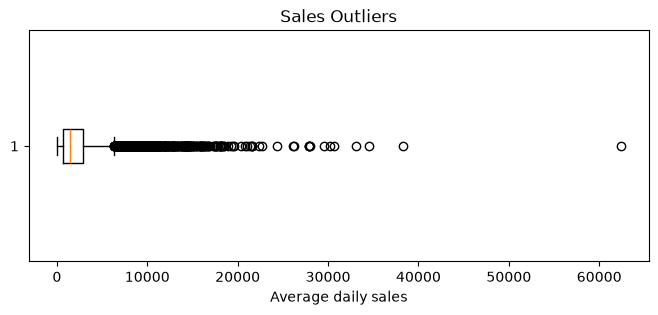

In [13]:
plt.figure(figsize=(8,3))
plt.boxplot(target, vert=False, showfliers=True)

plt.xlabel("Average daily sales")
plt.title("Sales Outliers")

plt.show()

The mean ($2349.19) is a lot greater than the median ($1484), which tells us the data is right-skewed. A small number of high-sales retailers are bringing the average up.

The values are very spread out since std > mean
max is a lot greater than our median (unusually high sales retailers)

We will perform a logarithmic transformation of the target variable to improve predictive accuracy

### Log Transformation Target: avg_daily_sales

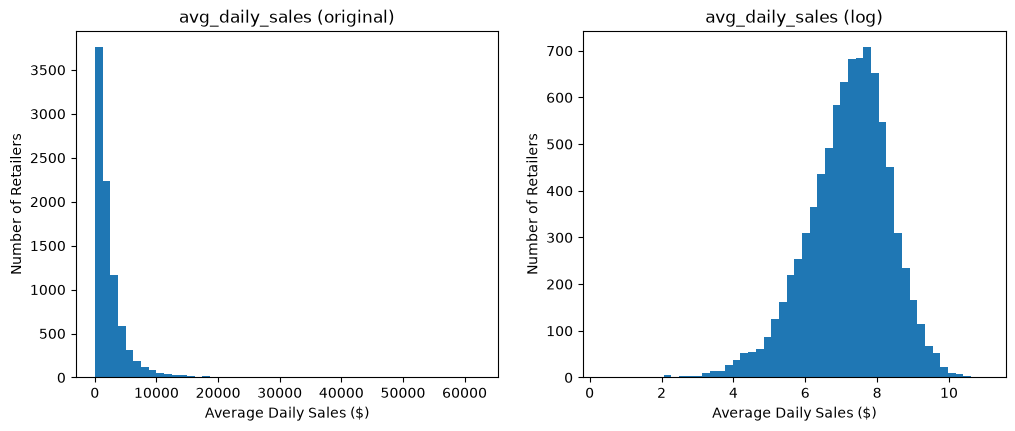

original skew value: 4.4
after log skew value: -0.64


In [14]:
# Taget variable overview
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Original sales distribution 
ax[0].hist(target, bins=50)
ax[0].set_title("avg_daily_sales (original)")
ax[0].set_xlabel("Average Daily Sales ($)")
ax[0].set_ylabel("Number of Retailers")

# Sales distribution after log transform
ax[1].hist(np.log1p(target), bins=50)
ax[1].set_title("avg_daily_sales (log)")
ax[1].set_xlabel("Average Daily Sales ($)")
ax[1].set_ylabel("Number of Retailers")

plt.show()

print("original skew value:", round(target.skew(), 2))
print("after log skew value:", round(np.log1p(target).skew(), 2))

Insights:
Left original graph: The distribution is piled on the left and has a very long right tail. The skewest is 4.4 (a lot greater than 1)
Right after log: The shape is more like a bell curve centered around 7-8, and skwest falls to -0.64
How does this help? A few hugh sale stores will no longer dominate the training. 

## Business Type, Chain & NYC

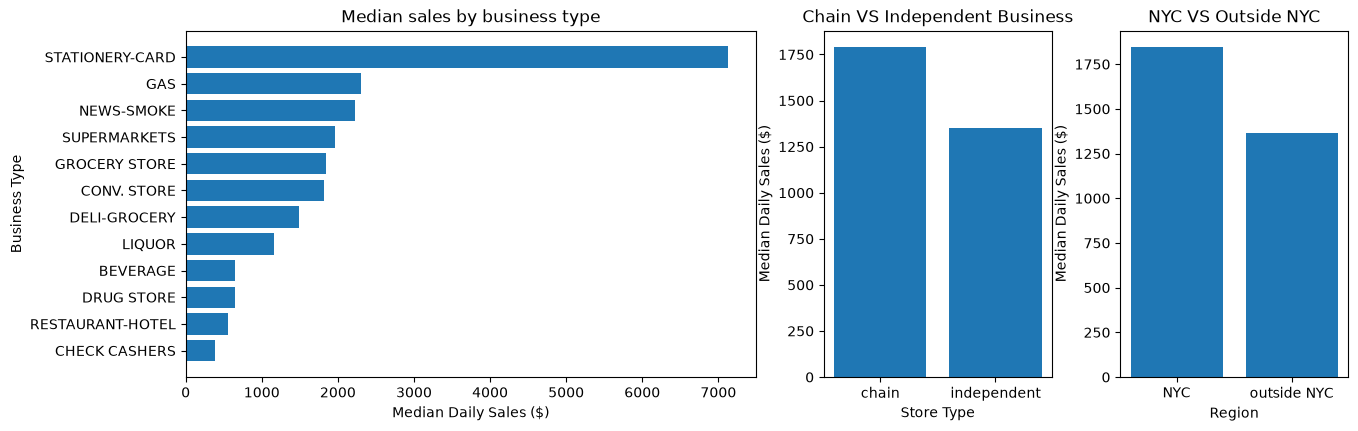

bg_geoid
NYC            1845.81
outside NYC    1367.75
Name: avg_daily_sales, dtype: float64
chain
chain          1790.37
independent    1352.61
Name: avg_daily_sales, dtype: float64


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15,4.5), gridspec_kw={"width_ratios": [2.5, 1, 1]})

counts = df_imputed["bustype"].value_counts()
#business type has at least 100 stores
store_count = counts[counts >= 100].index

bustype_median = df_imputed[df_imputed['bustype'].isin(store_count)].groupby("bustype")["avg_daily_sales"].median().sort_values()

# Median Sales by Business Type
ax[0].barh(bustype_median.index, bustype_median.values)
ax[0].set_title("Median sales by business type")
ax[0].set_xlabel("Median Daily Sales ($)")
ax[0].set_ylabel("Business Type")

# Chain 
chain_median = df_imputed.groupby("chain")["avg_daily_sales"].median()
ax[1].bar(chain_median.index, chain_median.values)
ax[1].set_title("Chain VS Independent Business")
ax[1].set_xlabel("Store Type")
ax[1].set_ylabel("Median Daily Sales ($)")

# In NYC or outside NYC 

nyc = df_imputed["bg_geoid"].astype("int64").astype(str).str[2:5].isin(["005", "047", "061", "081", "085"])
region = nyc.map({True: "NYC", False: "outside NYC"})
region_median = df_imputed.groupby(region)["avg_daily_sales"].median()
ax[2].bar(region_median.index, region_median.values)
ax[2].set_title("NYC VS Outside NYC")
ax[2].set_xlabel("Region")
ax[2].set_ylabel("Median Daily Sales ($)")


plt.show()
print(region_median.round(2))
print(chain_median.round(2))

Chain stores sale more then independent store while NYC sells more than the rest of the state. 

## Features's with Sales Correlation & Relationship

Focus on Nearby Business & competition, Walkability & Traffic, Population, Income, Poverty, Employment, 

                               pearson_w_sales  spearman_w_sales  \
feature                                                            
commercial_places_within_1_mi            0.154             0.134   
competitors_within_1_mi                  0.147             0.130   
aadt_count                               0.094             0.101   
NatWalkInd                               0.114             0.086   
rac_c000                                 0.065             0.075   
median_household_income                  0.039             0.055   
total_population                         0.038             0.048   
family_households_proportion             0.012             0.028   
wac_c000                                 0.004             0.020   
unemployment_rate                        0.026             0.018   
poverty_rate                             0.002            -0.027   
rac_ce01_prop                           -0.048            -0.091   

                               person_log_w_sal

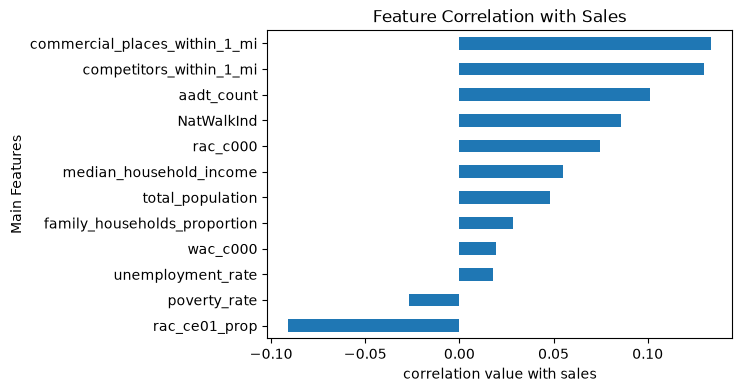

In [18]:

# original_df = pd.read_parquet('../data/modeling/train_data.parquet').copy()
log_avg_sales = np.log1p(df_imputed['avg_daily_sales'])
rows = []

main_features = ['competitors_within_1_mi',
       'aadt_count','median_household_income', 'total_population', 'poverty_rate','unemployment_rate', 
       'family_households_proportion', 'NatWalkInd', 'commercial_places_within_1_mi', 'rac_c000', 'rac_ce01_prop', 'wac_c000'
       ]

for features in main_features:
    x = pd.to_numeric(df_imputed[features], errors='coerce')
    rows.append({
        'feature': features,
        'pearson_w_sales': x.corr(target, method='pearson'),
        'spearman_w_sales': x.corr(target, method='spearman'),
        'person_log_w_sales': x.corr(np.log1p(target))
    }
    )
correlation_table = pd.DataFrame(rows).set_index('feature')
print(correlation_table.round(3).sort_values('spearman_w_sales', ascending=False))

corr_spearman = df_imputed[main_features].corrwith(log_avg_sales, method="spearman").sort_values()
corr_spearman.plot.barh(figsize=(6,4),)

plt.title("Feature Correlation with Sales")
plt.ylabel("Main Features")
plt.xlabel("correlation value with sales")
plt.show()



Insights:
The values showed weak correlation with sales.Commercial_places_within_1mi being the highest correlation followed by competitors_within_1mi.
The negative value for poverty_rate and rac_ce01_prop showed the lower income areas sell a little less. 
The overview should the neighbohood variable may not have huge impact with the sales.  

ScatterPlot: Features VS Sales

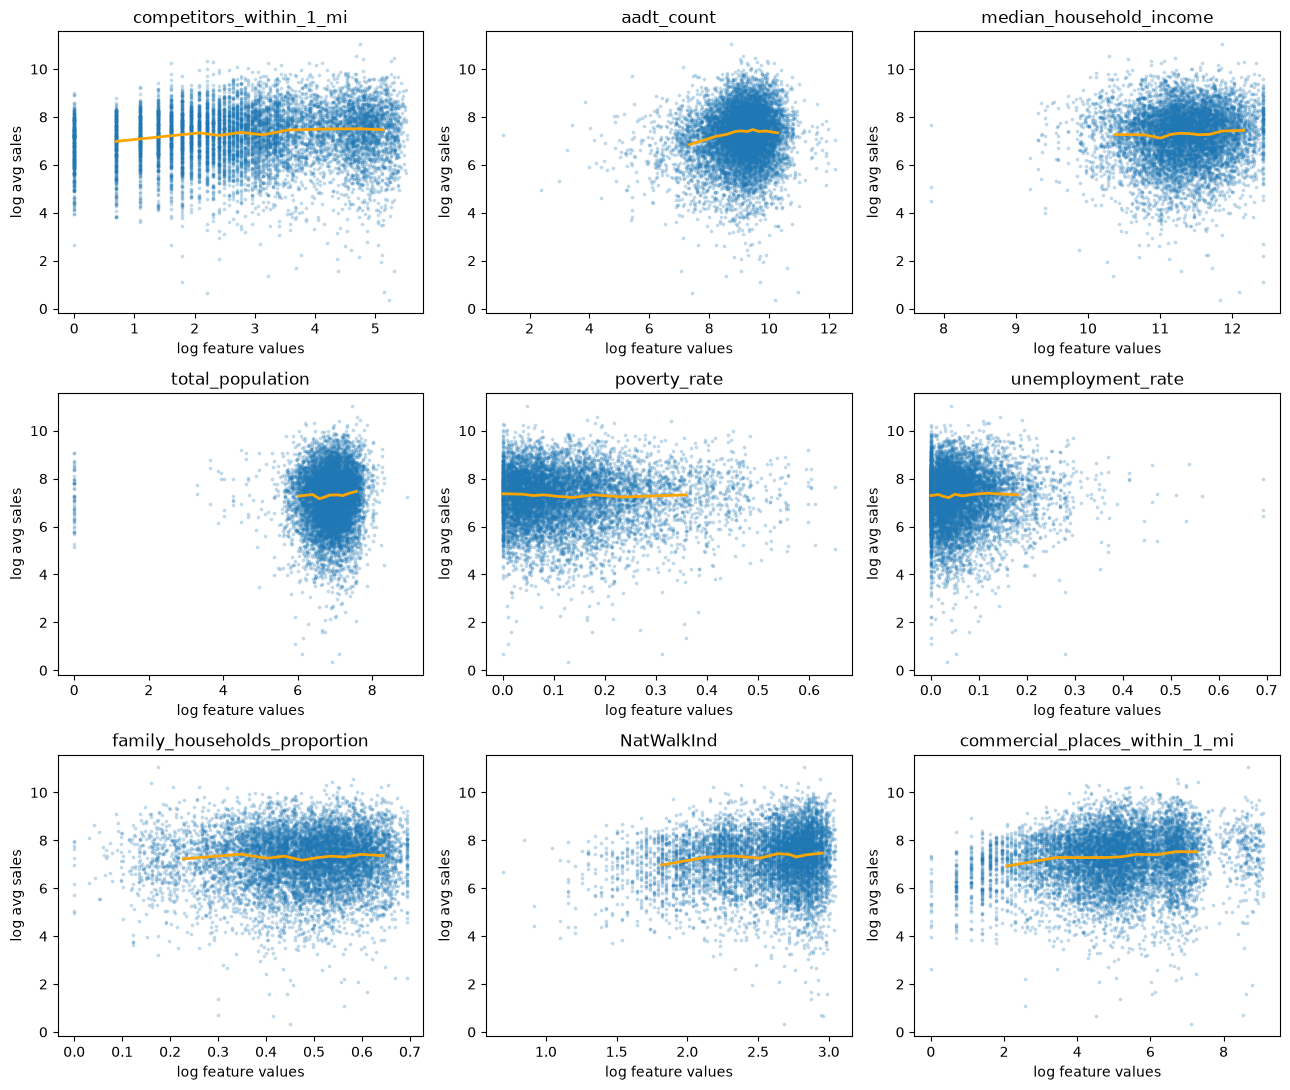

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(13,11))

for ax, col in zip(axes.flat, main_features):
    data = pd.DataFrame({
        "x": np.log1p(df_imputed[col]),
        #"x": (df[col]),
        "y": log_avg_sales
    }).dropna()

    ax.scatter(x=data["x"], y=data["y"], s=3, alpha=0.2)

    #plot medain as a trend line
    trend = data.groupby(pd.qcut(data["x"], 10, duplicates="drop"), observed=True).median()
    ax.plot(trend["x"], trend["y"], color="orange", linewidth=2)
    ax.set_title(col)
    ax.set_ylabel("log avg sales")
    ax.set_xlabel("log feature values")


plt.tight_layout()
plt.show()

Insight: <br> Blue plots: individual observations. 
<br> Organe Line: shows the overall trend 

<br>Upward slope -> positive relationship: competitors, traffic, commerical plates. The trend has a slight rise
<br>Downward slope -> negative relationship 
<br>Almost Flat -> weak or no relationship: total_population, median household income, poverty rate, unemployment rate and damily households
<br>Accessibiility and commercial activity appear the be more strongly asspcoated with sales than socioeconomic characteristics

<!-- group = {
    "Traffic": ['aadt_count', 'aadt_lanes', 'dist_to_read_m'],
    "Nearby Places" :['commercial_places_within_1_mi','community_places_within_1_mi','competitors_within_1_mi'],
    "Walkability/Density": ['D1B', 'D1C', 'D3A', 'NatWalkInd'],
    "Jobs at the location": [c for c in features if c.startswith("wac_") ]
}
<!-- numeric_features = ['', ,
       'median_household_income', 'total_population', 'age_18_29_proportion', 'age_30_64_proportion',
       'poverty_rate', 'bachelors_degree_proportion_25plus', 'post_grad_degree_proportion_25plus',
       'labor_force_participation_rate', 'unemployment_rate', 'owner_occupied_proportion',
       'family_households_proportion', 'no_vehicle_households_proportion',
        -->

                              features  avg corr  \
groups                                             
Nearby Places                        3  0.129130   
Walkability/Density                  4  0.126435   
Jobs where people live (RAC)         3  0.055283   
Traffic                              3  0.050177   
Demographics                        12  0.041644   
Jobs at the location                23  0.031510   

                                             strongest feature  
groups                                                          
Nearby Places                    commercial_places_within_1_mi  
Walkability/Density                                        D1B  
Jobs where people live (RAC)                     rac_ce01_prop  
Traffic                                             aadt_count  
Demographics                  no_vehicle_households_proportion  
Jobs at the location                                 wac_cns01  


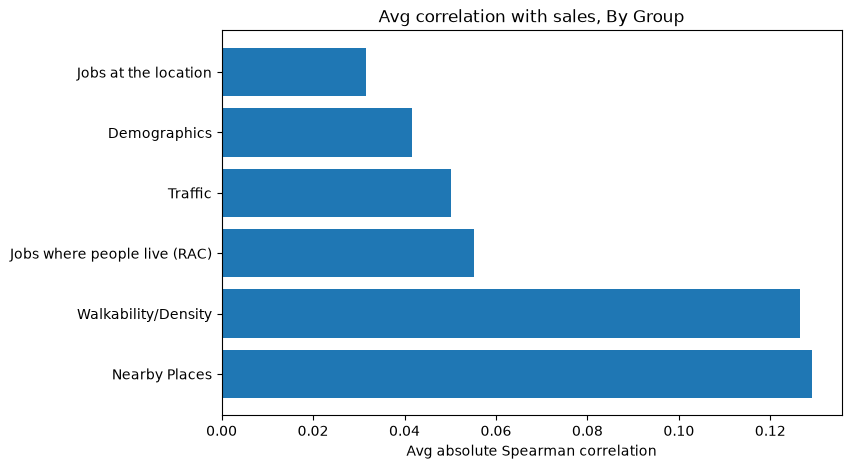

In [ ]:
features = [data for data in df_imputed.select_dtypes("number").columns if data not in ["avg_daily_sales", "longitude", "latitude"]]


groups = {
    "Traffic": ['aadt_count', 'aadt_lanes', 'dist_to_read_m'],
    "Nearby Places" :['commercial_places_within_1_mi','community_places_within_1_mi','competitors_within_1_mi'],
    "Walkability/Density": ['D1B', 'D1C', 'D3A', 'NatWalkInd'],
    "Jobs at the location": [c for c in features if c.startswith("wac_")],
    "Jobs where people live (RAC)":[c for c in features if c.startswith("rac_") ]
}

# the rest group it in demographics
groups["Demographics"] = [c for c in features if c not in sum(groups.values(), [])]

all_corr = df_imputed[features].corrwith(log_avg_sales, method="spearman")

summary = pd.DataFrame([
    { "groups": g, "features": len(cols),
    "avg corr": all_corr[cols].abs().mean(),
    "strongest feature": all_corr[cols].abs().idxmax()}
    for g, cols in groups.items()
]).set_index("groups").sort_values("avg corr", ascending=False)

print(summary)


fig, ax = plt.subplots(figsize=(8,5))

ax.barh(summary.index, summary["avg corr"])
ax.set_title("Avg correlation with sales, By Group")
ax.set_xlabel("Avg absolute Spearman correlation")

plt.show()


Insights: THis graph shows which group of features matters the most and find the strongest feature among each group. 
As we can see the best group average was about 0.13, not a very strong correlation. 

#### Median Daily Sales for the lowest to the highest fifth of stores on each feature

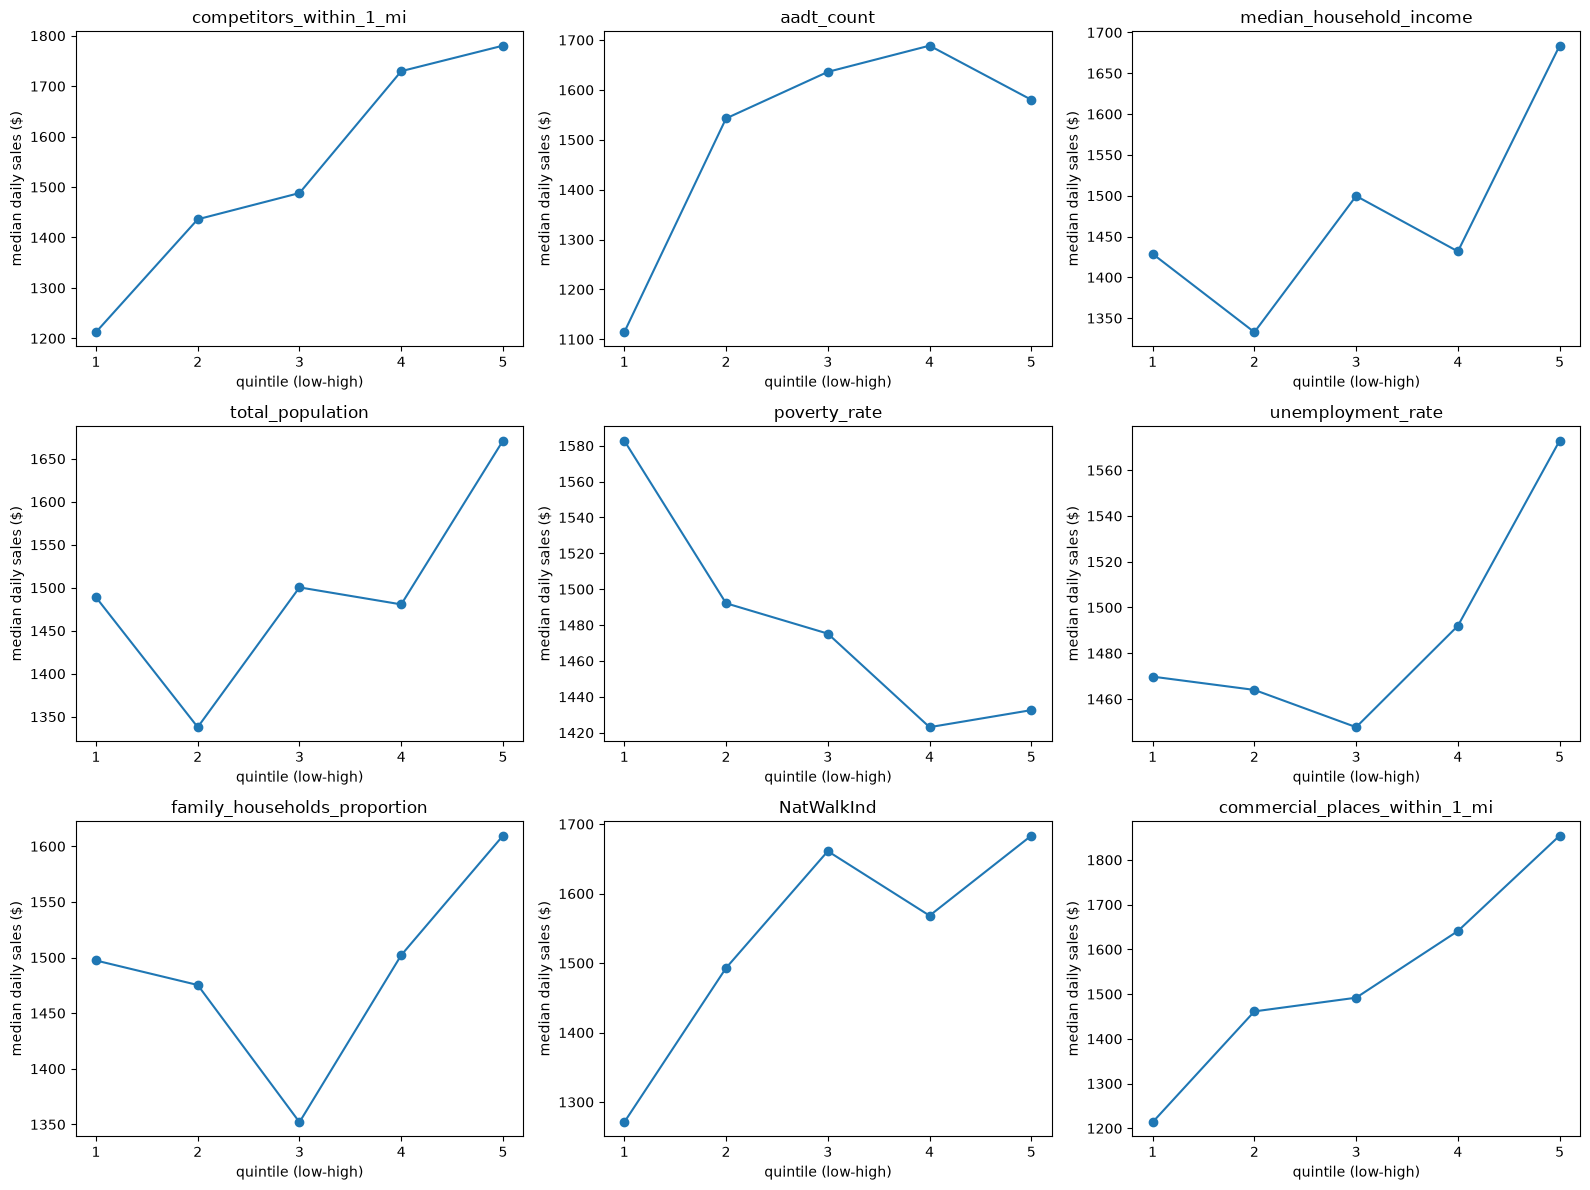

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16,12))
TARGET = "avg_daily_sales"
for ax, feature in zip(axes.flat, main_features):
    data = df_imputed[[feature, TARGET]].apply(pd.to_numeric, errors="coerce").dropna()
    group = pd.qcut(data[feature].rank(method="first"), 5, labels=False) + 1
    data.groupby(group)[TARGET].median().plot(ax=ax, marker="o", title=feature)

    ax.set_xticks(range(1,6))
    ax.set_xlabel("quintile (low-high)")
    ax.set_ylabel("median daily sales ($)")


plt.tight_layout()
plt.show()

Insight: This graph shows the median sales from the lowest to the highest fifth of stores on each feature.
The nearby commercial places and competitors shows the clearest upward lines, which shows the busy areas have higher selling stores
The traffic aadt_count showed the biggest jump is from the lowest fifth to the second. Indicating the low=traffic spots are the weakest. 